In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [ ]:
# Cargo los datos
archivo = "datosPosicion.csv"
datosPos = pd.read_csv(archivo)
print(datosPos.head())
print(f'Cantidad de datos n: {len(datosPos["tiempo"])}')
print(f'Media de la posición: {np.mean(datosPos["posicion"])}')

   Unnamed: 0  tiempo  posicion
0           1     0.0  4.639524
1           2     0.1  5.969823
2           3     0.2  8.758708
3           4     0.3  8.270508
4           5     0.4  9.329288
Cantidad de datos n: 21
Media de la posición: 15.284031063976448


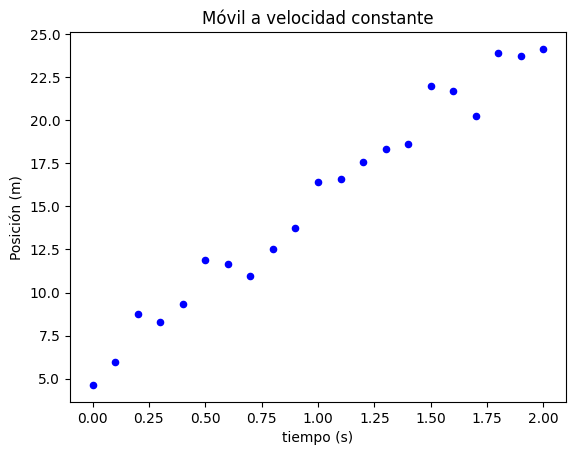

In [ ]:
#Gráfico de dispersión
plt.figure()
plt.scatter(datosPos['tiempo'], datosPos['posicion'], s=20, c='blue')
plt.title("Móvil a velocidad constante")
plt.xlabel("tiempo (s)")
plt.ylabel("Posición (m)")
plt.savefig("figura1.pdf")
plt.show()

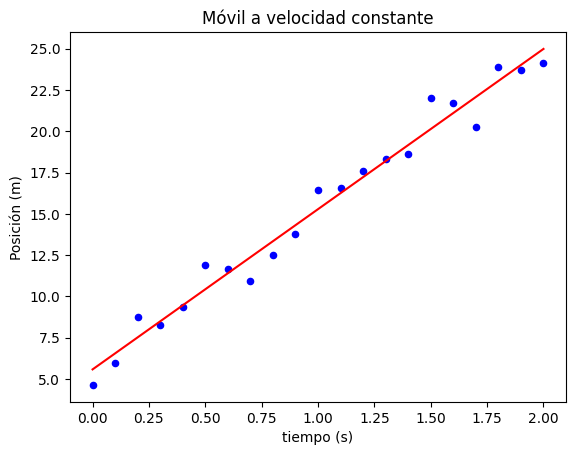

In [ ]:
#Dibujo con la regresión lineal
plt.figure()
plt.scatter(datosPos['tiempo'], datosPos['posicion'], s=20, c='blue')
plt.plot(datosPos['tiempo'], np.polyval(np.polyfit(datosPos['tiempo'], datosPos['posicion'], 1), datosPos['tiempo']), color='red')
plt.title("Móvil a velocidad constante")
plt.xlabel("tiempo (s)")
plt.ylabel("Posición (m)")
plt.savefig("figura3.pdf")
plt.show()

In [ ]:
#Regresión lineal simple
n = len(datosPos['tiempo'])
xi = datosPos['tiempo']
yi = datosPos['posicion']
Sxx = np.sum(xi**2) - (np.sum(xi)**2) / n
Sxy = np.sum(xi * yi) - (np.sum(xi) * np.sum(yi)) / n
beta1_est = Sxy / Sxx
beta0_est = np.mean(yi) - beta1_est * np.mean(xi)

print(f'Sxx: {Sxx}')
print(f'Sxy: {Sxy}')

print(f'Estimación de beta0 (Intercept): {beta0_est}')
print(f'Estimación de beta1 (Slope): {beta1_est}')


Sxx: 7.70000000000001
Sxy: 74.72358401032119
Estimación de beta0 (Intercept): 5.57966950419449
Estimación de beta1 (Slope): 9.70436155978196


In [ ]:
# Usando sklearn
model = LinearRegression().fit(xi.values.reshape(-1, 1), yi)
print(f'Intercept: {model.intercept_}, Slope: {model.coef_[0]}')


Intercept: 5.579669504194467, Slope: 9.704361559781983


In [ ]:
# Calculo de las desviaciones de beta0 y beta1
SST = np.sum(yi**2) - n * (np.mean(yi)**2)
SSE = SST - beta1_est * Sxy
varSigma_est = SSE / (n - 2)

desvBeta1 = np.sqrt(varSigma_est / Sxx)
desvBeta0 = np.sqrt(varSigma_est * (1 / n + (np.mean(xi)**2) / Sxx))

print(f'Desviación típica de beta0: {desvBeta0}')
print(f'Desviación típica de beta1: {desvBeta1}')


Desviación típica de beta0: 0.4179061182014073
Desviación típica de beta1: 0.3574764433277663


In [ ]:
#Valor de estadístico de prueba
T0 = beta1_est / np.sqrt(varSigma_est / Sxx)
print(f'T0: {T0}')
p_valor = 2 * (1 - stats.t.cdf(T0, n - 2))
print(f'p-valor de beta1: {p_valor}')

#Valores críticos
alfa = 0.05
tcrit1 = stats.t.ppf(0.05 / 2, n - 2)
tcrit2 = stats.t.ppf(1 - 0.05 / 2, n - 2)
print(f'Valor crítico postivo tomando alfa = 0.05: {tcrit2}')

T0: 27.146856082161854
p-valor de beta1: 0.0
Valor crítico postivo tomando alfa = 0.05: 2.093024054408263


In [ ]:
#Prueba de H0: beta1 = 10 o distinto
t0 = (beta1_est - 10) / np.sqrt(varSigma_est / Sxx)
print(f't0: {t0}')
p_valor = 2 * (stats.t.cdf(t0, n - 2))
print(f'p-valor de beta1: {p_valor}')


t0: -0.8270151662748093
p-valor de beta1: 0.4184943117900731
